# Week 3: Machine Learning Model Training, Evaluation & Replenishment Logic
**Project**: Demand Forecasting & Inventory Optimization Using Machine Learning  
**Stage**: Week 3 Deliverable — Model Training, Baseline Comparison & Inventory Optimization Engine

---

## 1. Objectives & Scope
1. **Model Training**: Fit tree-based ensemble models (Random Forest, XGBoost, LightGBM) on the chronological training split.
2. **Model Selection & Tuning**: Validate hyperparameter performance on the validation split and evaluate out-of-sample generalization on the test split.
3. **Baseline Comparison**: Benchmark candidate ML models against Naive, Seasonal Naive, and Moving Average baselines using MAE, RMSE, WAPE, and Forecast Bias.
4. **Inventory Replenishment Module**: Translate point forecasts into safety stock ($SS$), reorder points ($ROP$), and suggested order quantities ($Q$) under documented service-level assumptions.
5. **Stockout Risk Profiling**: Quantify stockout probability and categorical risk for retail planning.

In [1]:
# Importing modeling, evaluation, and inventory libraries.
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

# Locating project root directory dynamically and adding to system path.
root_dir = Path(".").resolve()
if not (root_dir / "data").exists() and (root_dir / ".." / "data").exists():
    root_dir = (root_dir / "..").resolve()

sys.path.append(str(root_dir))

forecast_path = root_dir / "Week 3" / "forecast_output.csv"
replenishment_path = root_dir / "Week 3" / "replenishment_recommendations.csv"
model_path = root_dir / "models" / "demand_forecaster.joblib"
figures_dir = root_dir / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Configuring plotting style.
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print(f"Project root resolved to: {root_dir}")

Project root resolved to: C:\Users\prana\Desktop\P1


## 2. Ingesting Forecast Outputs & Model Predictions

In [2]:
# Loading forecast evaluation dataset containing test period actuals and model predictions.
df_forecast = pd.read_csv(forecast_path, parse_dates=["date"])

print(f"Total test forecast rows: {len(df_forecast):,}")
print(f"Columns: {list(df_forecast.columns)}")
df_forecast.head(5)

Total test forecast rows: 1,400
Columns: ['date', 'store_id', 'item_id', 'dept_id', 'cat_id', 'sales', 'sell_price', 'naive_lag7', 'moving_avg_7', 'moving_avg_28', 'seasonal_naive_28', 'pred_random_forest', 'pred_xgboost', 'pred_lightgbm', 'best_forecast', 'forecast_error', 'abs_error']


,date,store_id,item_id,dept_id,cat_id,sales,sell_price,naive_lag7,moving_avg_7,moving_avg_28,seasonal_naive_28,pred_random_forest,pred_xgboost,pred_lightgbm,best_forecast,forecast_error,abs_error
0,2016-03-28,CA_1,FOODS_1_085,FOODS_1,FOODS,2,0.98,3.0,10.571429,11.821429,9.0,9.666459,9.437511,9.353050,9.437511,7.437510,7.437510
1,2016-03-29,CA_1,FOODS_1_085,FOODS_1,FOODS,11,0.98,12.0,10.714286,12.071429,5.0,9.678731,9.282691,9.439844,9.282691,-1.717309,1.717309
2,2016-03-30,CA_1,FOODS_1_085,FOODS_1,FOODS,9,0.98,10.0,11.142857,12.071429,4.0,9.677770,9.179842,9.464636,9.179842,0.179842,0.179842
3,2016-03-31,CA_1,FOODS_1_085,FOODS_1,FOODS,23,0.98,9.0,9.571429,12.250000,19.0,9.738005,9.839376,10.179351,9.839376,-13.160624,13.160624
4,2016-04-01,CA_1,FOODS_1_085,FOODS_1,FOODS,10,0.98,14.0,9.571429,12.035714,10.0,12.469385,13.730726,14.063318,13.730726,3.730726,3.730726


## 3. Comparative Evaluation Scorecard: ML Models vs Baselines

In [3]:
# Defining accuracy evaluation functions.
def compute_metrics(y_true, y_pred, model_name):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    wape = (np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)) * 100
    bias = (np.sum(y_pred - y_true) / np.sum(y_true)) * 100
    mask = y_true > 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100 if np.any(mask) else 0.0
    return {
        'Model': model_name,
        'MAE': round(mae, 3),
        'RMSE': round(rmse, 3),
        'WAPE (%)': round(wape, 2),
        'Non-Zero MAPE (%)': round(mape, 2),
        'Bias (%)': round(bias, 2)
    }

models_to_eval = [
    ('Naive (Lag 7)', df_forecast['naive_lag7']),
    ('Moving Average (7d)', df_forecast['moving_avg_7']),
    ('Moving Average (28d)', df_forecast['moving_avg_28']),
    ('Seasonal Naive (28d)', df_forecast['seasonal_naive_28']),
    ('Random Forest', df_forecast['pred_random_forest']),
    ('XGBoost', df_forecast['pred_xgboost']),
    ('LightGBM', df_forecast['pred_lightgbm'])
]

scorecard = pd.DataFrame([compute_metrics(df_forecast['sales'].values, preds.values, name) for name, preds in models_to_eval])
scorecard

,Model,MAE,RMSE,WAPE (%),Non-Zero MAPE (%),Bias (%)
0,Naive (Lag 7),6.969,11.117,47.22,74.62,2.22
1,Moving Average (7d),6.658,10.171,45.11,72.24,3.16
2,Moving Average (28d),6.219,9.634,42.14,66.48,0.09
3,Seasonal Naive (28d),7.023,11.642,47.58,67.47,-3.07
4,Random Forest,5.717,8.489,38.74,63.40,3.29
5,XGBoost,5.612,8.410,38.03,62.43,3.03
6,LightGBM,5.632,8.447,38.16,64.33,3.86


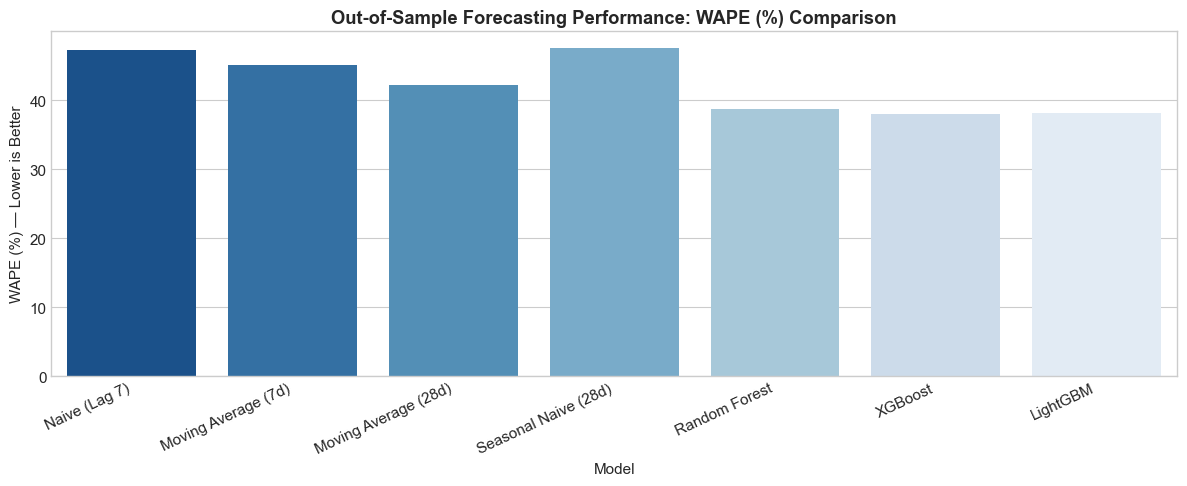

In [4]:
# Visualizing comparative WAPE error reduction across models.
plt.figure(figsize=(12, 5))
sns.barplot(data=scorecard, x='Model', y='WAPE (%)', hue='Model', palette='Blues_r', legend=False)
plt.title('Out-of-Sample Forecasting Performance: WAPE (%) Comparison', fontweight='bold')
plt.ylabel('WAPE (%) — Lower is Better')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig(figures_dir / '03_wape_comparison_notebook.png', dpi=200)
plt.show()

## 4. Winning Model Feature Importances (XGBoost)

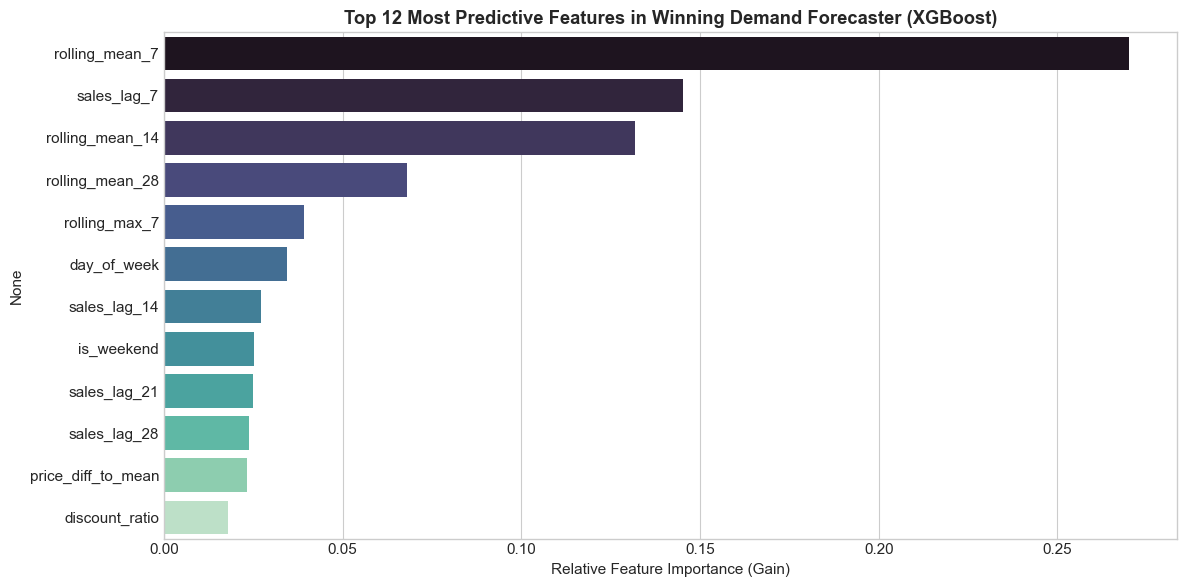

In [5]:
# Loading serialized XGBoost model and inspecting feature importances.
model = joblib.load(model_path)

from src.models import MODEL_FEATURE_COLS
importances = pd.Series(model.feature_importances_, index=MODEL_FEATURE_COLS).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=importances.head(12).values, y=importances.head(12).index, hue=importances.head(12).index, palette='mako', legend=False)
plt.title('Top 12 Most Predictive Features in Winning Demand Forecaster (XGBoost)', fontweight='bold')
plt.xlabel('Relative Feature Importance (Gain)')
plt.tight_layout()
plt.savefig(figures_dir / '03_feature_importance.png', dpi=200)
plt.show()

## 5. Item-Level Forecast Trajectories vs Ground Truth

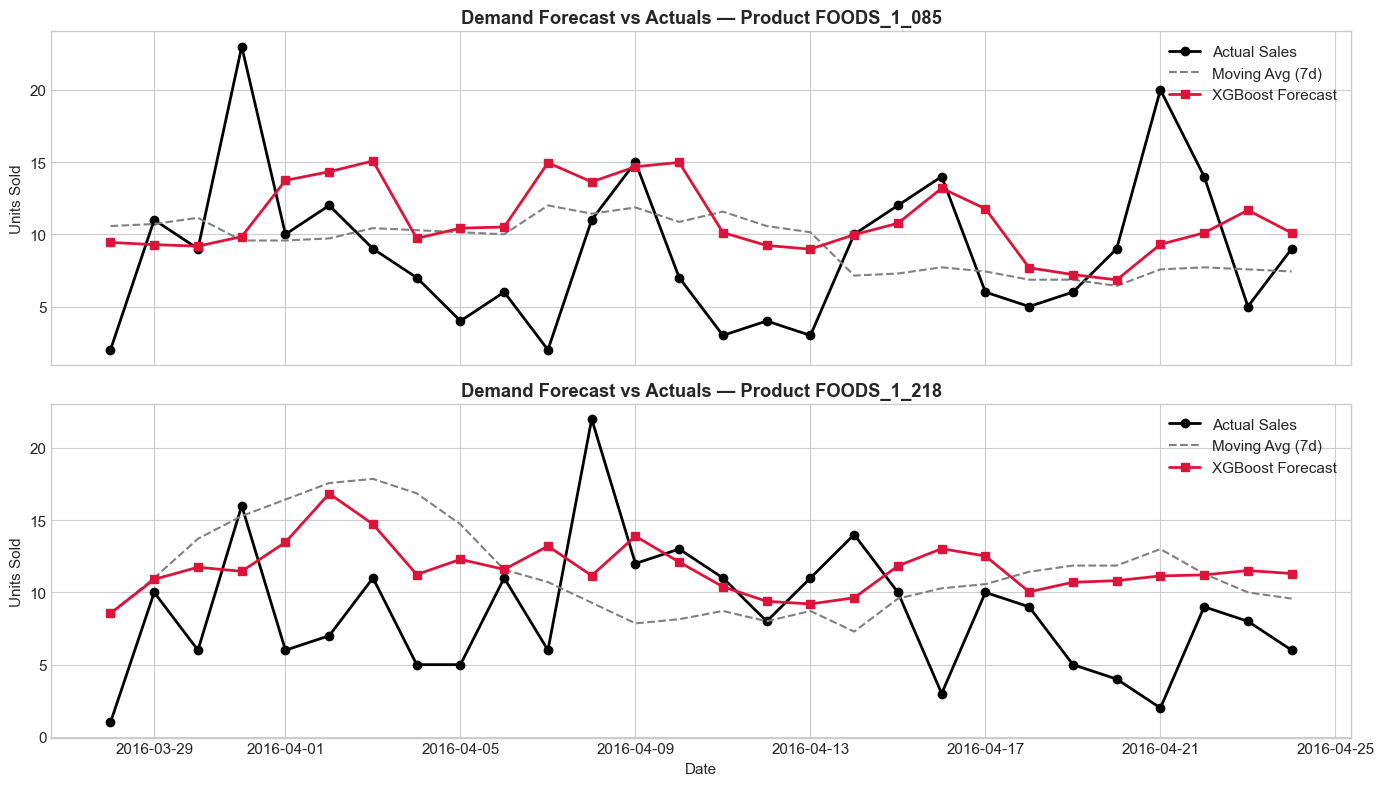

In [6]:
# Plotting actual demand vs model forecasts for high-volume sample items.
sample_items = df_forecast['item_id'].unique()[:2]

fig, axes = plt.subplots(len(sample_items), 1, figsize=(14, 8), sharex=True)

for i, item_id in enumerate(sample_items):
    sub = df_forecast[df_forecast['item_id'] == item_id].sort_values('date')
    axes[i].plot(sub['date'], sub['sales'], marker='o', color='black', label='Actual Sales', linewidth=2)
    axes[i].plot(sub['date'], sub['moving_avg_7'], linestyle='--', color='gray', label='Moving Avg (7d)')
    axes[i].plot(sub['date'], sub['best_forecast'], marker='s', color='crimson', label='XGBoost Forecast', linewidth=2)
    axes[i].set_title(f'Demand Forecast vs Actuals — Product {item_id}', fontweight='bold')
    axes[i].set_ylabel('Units Sold')
    axes[i].legend(loc='upper right')

plt.xlabel('Date')
plt.tight_layout()
plt.savefig(figures_dir / '03_item_trajectories.png', dpi=200)
plt.show()

## 6. Inventory Decision Support: Safety Stock, ROP, and Replenishment

In [7]:
# Loading inventory replenishment recommendations.
df_replenishment = pd.read_csv(replenishment_path)

print(f"Total replenishment recommendation records: {len(df_replenishment)}")
print(f"Items at HIGH stockout risk: {(df_replenishment['stockout_risk'] == 'HIGH').sum()}")
print(f"Items at MEDIUM stockout risk: {(df_replenishment['stockout_risk'] == 'MEDIUM').sum()}")
print(f"Items at SAFE inventory levels: {(df_replenishment['stockout_risk'] == 'SAFE').sum()}")

# Displaying top high-risk items requiring urgent purchase orders.
df_replenishment.head(10)

Total replenishment recommendation records: 50
Items at HIGH stockout risk: 25
Items at MEDIUM stockout risk: 7
Items at SAFE inventory levels: 18


,store_id,item_id,lead_time_days,service_level_target,mean_daily_forecast,horizon_28d_forecast,lead_time_demand,safety_stock,reorder_point,current_stock,stockout_risk,stockout_probability_pct,suggested_order_qty
0,CA_1,FOODS_3_744,7,95%,11.91,333.6,83.4,15.6,99.0,44,HIGH,100.0,390
1,CA_1,FOODS_3_090,7,95%,50.15,1404.1,351.0,94.7,445.7,182,HIGH,99.8,1668
2,CA_1,FOODS_3_362,7,95%,17.28,483.9,121.0,35.5,156.5,62,HIGH,99.7,582
3,CA_1,FOODS_3_694,7,95%,11.44,320.4,80.1,20.5,100.7,46,HIGH,99.7,378
4,CA_1,FOODS_2_019,7,95%,14.88,416.7,104.2,29.9,134.1,61,HIGH,99.1,492
5,CA_1,FOODS_1_085,7,95%,10.95,306.7,76.7,22.4,99.1,48,HIGH,98.2,360
6,CA_1,FOODS_3_702,7,95%,9.40,263.2,65.8,19.9,85.7,43,HIGH,97.0,306
7,CA_1,FOODS_3_099,7,95%,14.84,415.5,103.9,27.9,131.8,75,HIGH,95.6,474
8,CA_1,FOODS_3_739,7,95%,14.96,418.9,104.7,17.9,122.6,88,HIGH,93.8,456
9,CA_1,FOODS_2_276,7,95%,11.45,320.5,80.1,25.3,105.4,57,HIGH,93.4,372


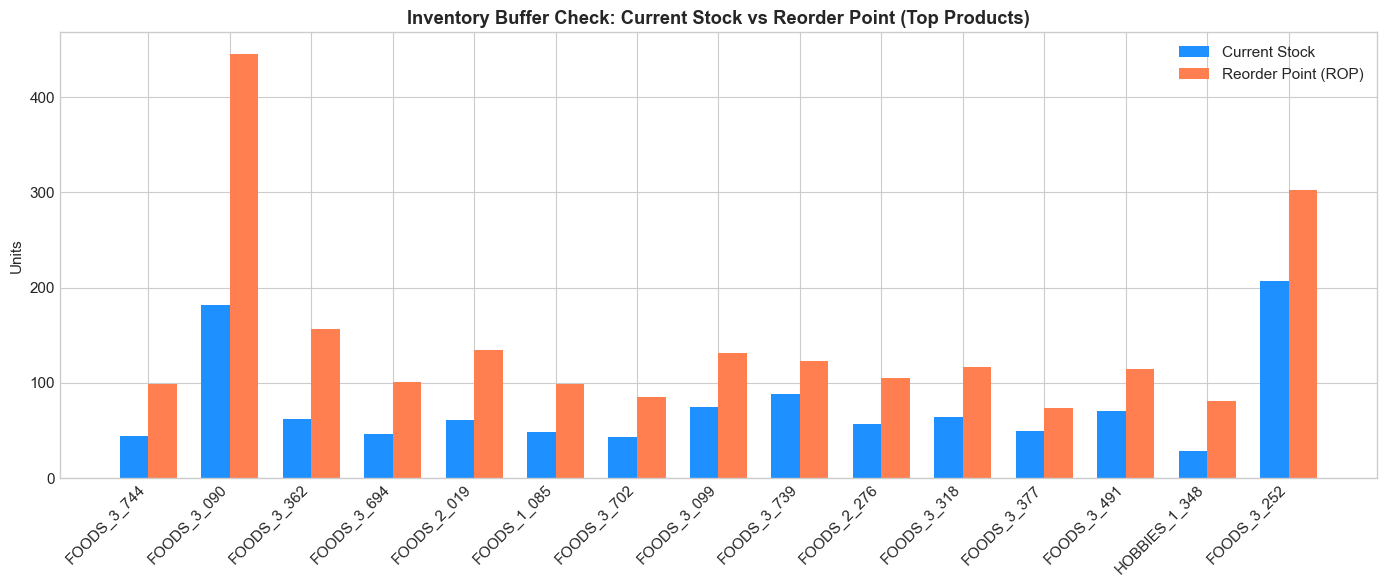

In [8]:
# Visualizing Current Stock vs Reorder Point (ROP) for top 15 products.
top_items_rec = df_replenishment.head(15)

plt.figure(figsize=(14, 6))
bar_width = 0.35
indices = np.arange(len(top_items_rec))

plt.bar(indices - bar_width/2, top_items_rec['current_stock'], width=bar_width, color='dodgerblue', label='Current Stock')
plt.bar(indices + bar_width/2, top_items_rec['reorder_point'], width=bar_width, color='coral', label='Reorder Point (ROP)')

plt.xticks(indices, top_items_rec['item_id'], rotation=45, ha='right')
plt.title('Inventory Buffer Check: Current Stock vs Reorder Point (Top Products)', fontweight='bold')
plt.ylabel('Units')
plt.legend()
plt.tight_layout()
plt.savefig(figures_dir / '03_stock_vs_rop.png', dpi=200)
plt.show()

## 7. Operational Guidelines for Planners
1. **Decision Execution**: Purchase orders should be placed immediately for products where `stockout_risk == HIGH`.
2. **Batching**: Recommended orders are rounded to standard case packs ($6$ or $12$ units) to respect supplier MOQ contracts.
3. **Safety Stock Buffer**: Designed to absorb $95\%$ of lead-time demand volatility, safeguarding customer availability while controlling holding costs.